In [2]:
%pip install torchvision scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split

project = Path.home() / "deep-learning-project1"
data = project / "data"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

torch.manual_seed(42)

Device: cuda


In [4]:
train_df = pd.read_csv(project / "train_labels.csv")
test_df = pd.read_csv(project / "test.csv")

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

train_paths = {p.name: p for p in data.rglob("train_*.png")}
test_paths = {p.name: p for p in data.rglob("test_*.png")}

print(len(train_paths), len(test_paths))
print(train_df.head())

50000 2000
   id         filename  label
0   0  train_00000.png      6
1   1  train_00001.png      9
2   2  train_00002.png      9
3   3  train_00003.png      4
4   4  train_00004.png      1


In [9]:
class CIFARCompetitionDataset(Dataset):
    def __init__(self, dataframe, image_paths, transform=None, labeled=True):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_paths = image_paths
        self.transform = transform
        self.labeled = labeled

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image = Image.open(self.image_paths[row["filename"]]).convert("RGB")

        if self.transform:
            image = self.transform(image)

        if self.labeled:
            return image, int(row["label"])

        return image

In [10]:
train_split, val_split = train_test_split(
    train_df,
    test_size=0.1,
    random_state=42,
    stratify=train_df["label"]
)

train_dataset = CIFARCompetitionDataset(
    train_split, train_paths, train_transform
)

val_dataset = CIFARCompetitionDataset(
    val_split, train_paths, test_transform
)

test_dataset = CIFARCompetitionDataset(
    test_df, test_paths, test_transform, labeled=False
)

train_loader = DataLoader(
    train_dataset, batch_size=128, shuffle=True,
    num_workers=4, pin_memory=True
)

val_loader = DataLoader(
    val_dataset, batch_size=256, shuffle=False,
    num_workers=4, pin_memory=True
)

test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False,
    num_workers=4, pin_memory=True
)

print(len(train_dataset), len(val_dataset), len(test_dataset))

45000 5000 2000


In [11]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels, 3,
            stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels, 3,
            padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.shortcut = nn.Sequential()

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels, 1,
                    stride=stride, bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        out = self.relu(out + identity)
        return out


class CustomResNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(3, 48, 3, padding=1, bias=False),
            nn.BatchNorm2d(48),
            nn.ReLU(inplace=True)
        )

        self.layers = nn.Sequential(
            ResidualBlock(48, 48),
            ResidualBlock(48, 48),

            ResidualBlock(48, 96, stride=2),
            ResidualBlock(96, 96),

            ResidualBlock(96, 192, stride=2),
            ResidualBlock(192, 192),

            ResidualBlock(192, 256, stride=2),
            ResidualBlock(256, 256)
        )

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.layers(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)


model = CustomResNet().to(device)

parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Trainable parameters: {parameters:,}")
assert parameters < 5_000_000

Trainable parameters: 3,828,282


In [12]:
epochs = 60

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer = optim.SGD(
    model.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4,
    nesterov=True
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=epochs
)

scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

In [13]:
train_losses = []
val_accuracies = []
best_accuracy = 0

for epoch in range(epochs):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        with torch.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss = total_loss / total
    train_accuracy = 100 * correct / total

    model.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_accuracy = 100 * val_correct / val_total

    scheduler.step()

    train_losses.append(train_loss)
    val_accuracies.append(val_accuracy)

    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            project / "best_resnet.pth"
        )

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Acc: {val_accuracy:.2f}% | "
        f"Best: {best_accuracy:.2f}%",
        flush=True
    )

Epoch 1/60 | Loss: 1.8785 | Train Acc: 35.57% | Val Acc: 46.08% | Best: 46.08%
Epoch 2/60 | Loss: 1.4942 | Train Acc: 54.22% | Val Acc: 55.40% | Best: 55.40%
Epoch 3/60 | Loss: 1.2853 | Train Acc: 64.50% | Val Acc: 65.88% | Best: 65.88%
Epoch 4/60 | Loss: 1.1621 | Train Acc: 70.55% | Val Acc: 72.62% | Best: 72.62%
Epoch 5/60 | Loss: 1.0576 | Train Acc: 75.34% | Val Acc: 76.82% | Best: 76.82%
Epoch 6/60 | Loss: 0.9936 | Train Acc: 78.46% | Val Acc: 75.02% | Best: 76.82%
Epoch 7/60 | Loss: 0.9509 | Train Acc: 80.30% | Val Acc: 76.54% | Best: 76.82%
Epoch 8/60 | Loss: 0.9197 | Train Acc: 81.74% | Val Acc: 79.98% | Best: 79.98%
Epoch 9/60 | Loss: 0.8995 | Train Acc: 82.67% | Val Acc: 78.58% | Best: 79.98%
Epoch 10/60 | Loss: 0.8761 | Train Acc: 83.78% | Val Acc: 79.86% | Best: 79.98%
Epoch 11/60 | Loss: 0.8638 | Train Acc: 84.18% | Val Acc: 80.06% | Best: 80.06%
Epoch 12/60 | Loss: 0.8483 | Train Acc: 84.95% | Val Acc: 82.16% | Best: 82.16%
Epoch 13/60 | Loss: 0.8344 | Train Acc: 85.50% | 

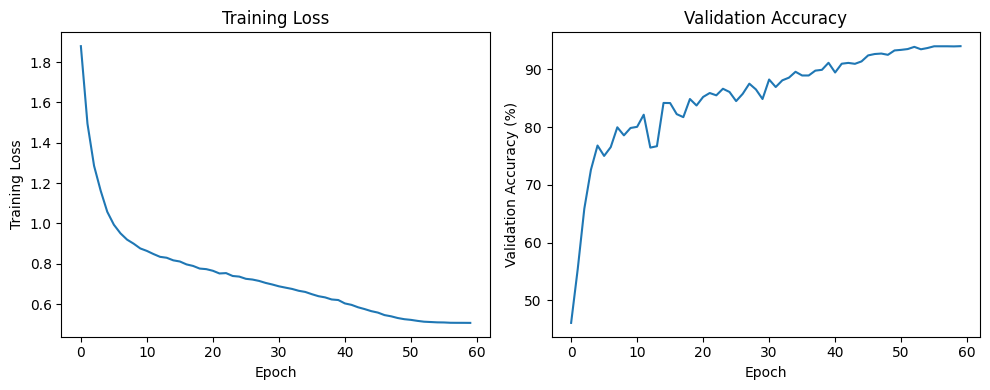

Best validation accuracy: 94.04%


In [14]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses)
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss")

plt.subplot(1, 2, 2)
plt.plot(val_accuracies)
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("Validation Accuracy")

plt.tight_layout()
plt.show()

print(f"Best validation accuracy: {best_accuracy:.2f}%")

In [15]:
model.load_state_dict(
    torch.load(
        project / "best_resnet.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()
predictions = []

with torch.no_grad():
    for images in test_loader:
        images = images.to(device)
        outputs = model(images)
        predictions.extend(outputs.argmax(1).cpu().tolist())

submission = pd.read_csv(project / "sample_submission.csv")
submission["label"] = predictions

submission.to_csv(project / "submission.csv", index=False)

print(submission.head())
print("Submission saved!")

   id  label
0   0      6
1   1      3
2   2      3
3   3      9
4   4      3
Submission saved!


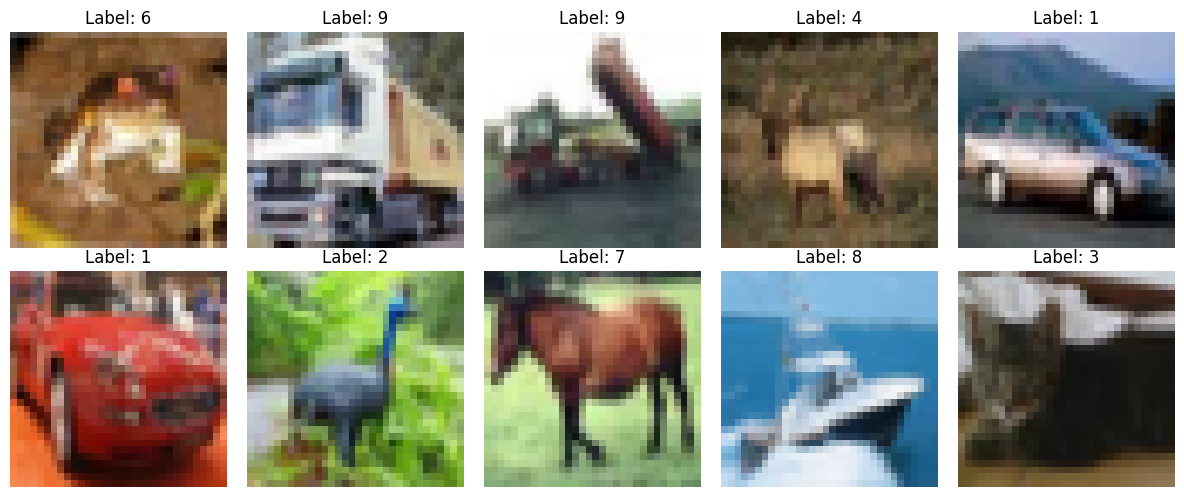

In [21]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    row = train_df.iloc[i]
    image = Image.open(train_paths[row["filename"]])

    ax.imshow(image)
    ax.set_title(f"Label: {row['label']}")
    ax.axis("off")

plt.tight_layout()
plt.show()

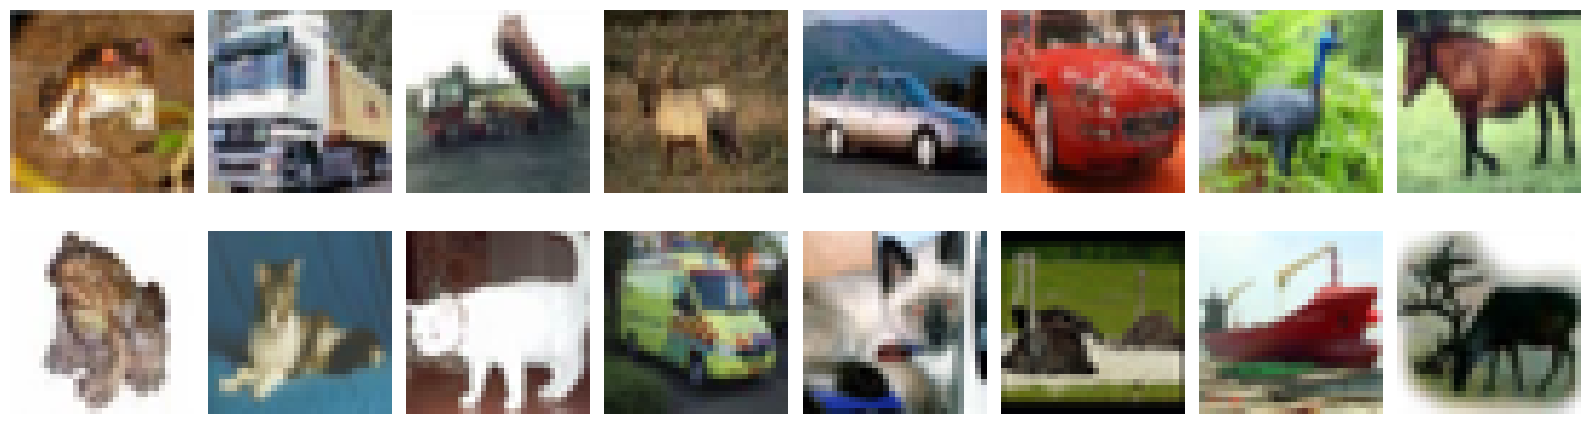

In [22]:
fig, axes = plt.subplots(2, 8, figsize=(16, 5))

for i in range(8):
    train_image = Image.open(
        train_paths[train_df.iloc[i]["filename"]]
    )
    test_image = Image.open(
        test_paths[test_df.iloc[i]["filename"]]
    )

    axes[0, i].imshow(train_image)
    axes[0, i].axis("off")

    axes[1, i].imshow(test_image)
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Training", fontsize=12)
axes[1, 0].set_ylabel("Kaggle Test", fontsize=12)

plt.tight_layout()
plt.show()

In [23]:
model.load_state_dict(
    torch.load(
        project / "best_resnet.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

print(f"Checkpoint validation accuracy: {100 * correct / total:.2f}%")

Checkpoint validation accuracy: 94.04%


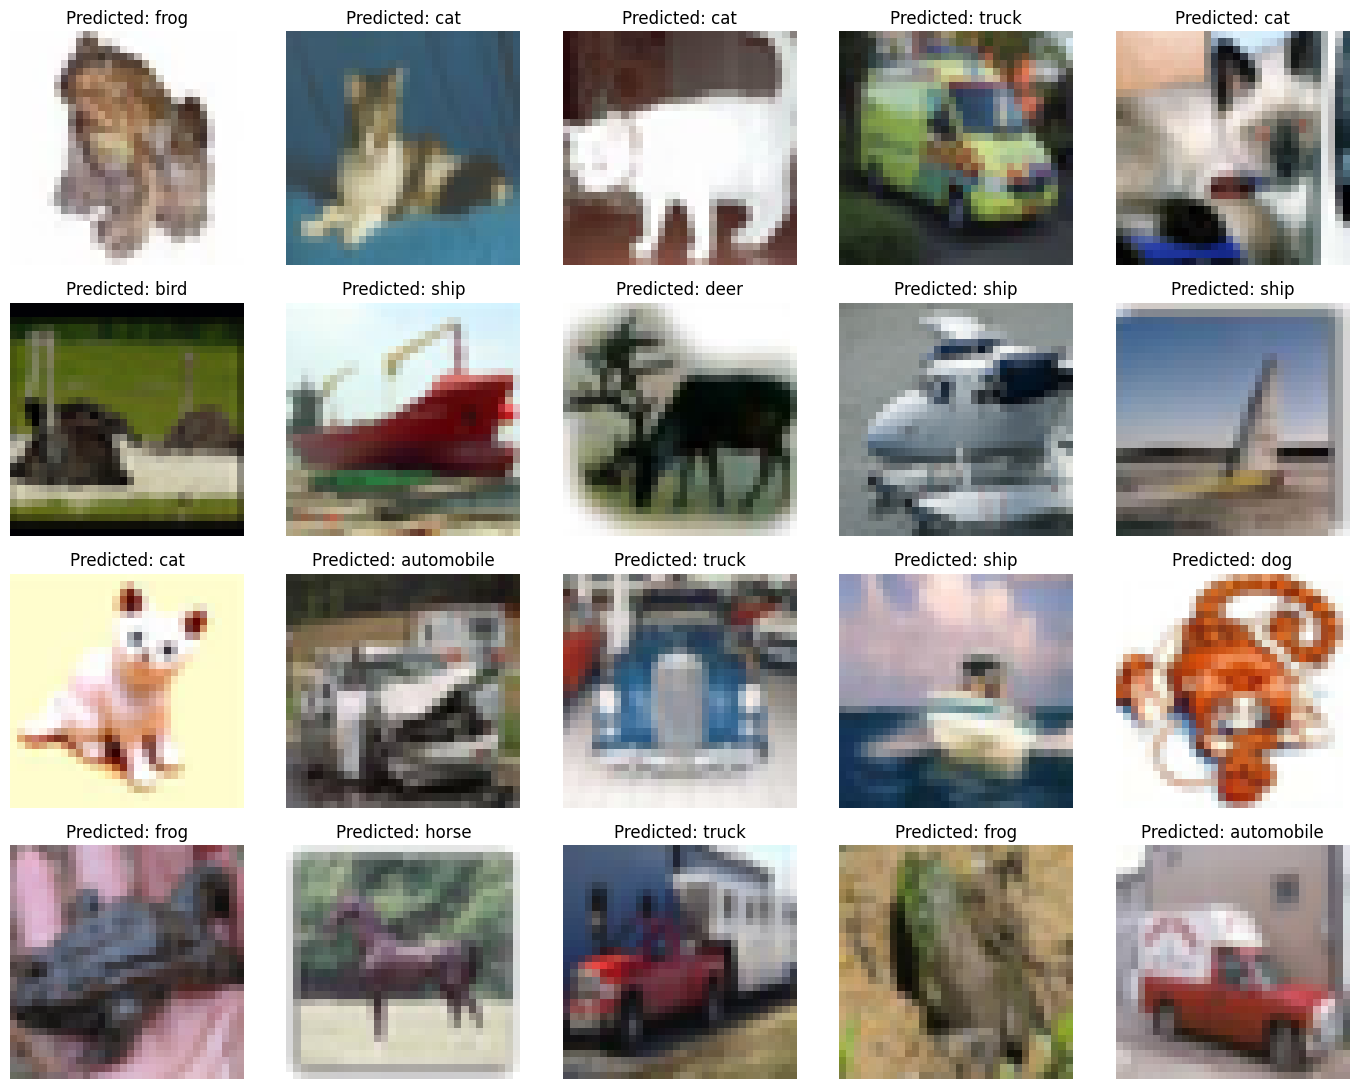

In [24]:
classes = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

fig, axes = plt.subplots(4, 5, figsize=(14, 11))

for i, ax in enumerate(axes.flat):
    row = test_df.iloc[i]
    image = Image.open(test_paths[row["filename"]])

    prediction = predictions[i]

    ax.imshow(image)
    ax.set_title(f"Predicted: {classes[prediction]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [25]:
model.eval()

tta_predictions = []

with torch.no_grad():
    for images in test_loader:
        images = images.to(device)

        # Original image predictions
        outputs1 = model(images)

        # Horizontally flipped image predictions
        flipped = torch.flip(images, dims=[3])
        outputs2 = model(flipped)

        # Average probabilities
        probs1 = torch.softmax(outputs1, dim=1)
        probs2 = torch.softmax(outputs2, dim=1)

        average = (probs1 + probs2) / 2

        tta_predictions.extend(
            average.argmax(dim=1).cpu().tolist()
        )

tta_submission = pd.read_csv(project / "sample_submission.csv")
tta_submission["label"] = tta_predictions

tta_submission.to_csv(
    project / "submission_tta.csv",
    index=False
)

print("TTA submission saved!")
print("Predictions changed:",
      sum(a != b for a, b in zip(predictions, tta_predictions)))

TTA submission saved!
Predictions changed: 103


In [1]:
train_transform_v2 = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.RandAugment(num_ops=2, magnitude=7),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    ),
    transforms.RandomErasing(
        p=0.25,
        scale=(0.02, 0.12)
    )
])

train_dataset_v2 = CIFARCompetitionDataset(
    train_split, train_paths, train_transform_v2
)

train_loader_v2 = DataLoader(
    train_dataset_v2,
    batch_size=128,
    shuffle=True,
    num_workers=4,
    pin_memory=True
)

print("Training examples:", len(train_dataset_v2))

NameError: name 'transforms' is not defined